In [1]:
import numpy as np
#import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

### Manifold: Circle

In [2]:
N = 1000 #sample size
r = 1 #radius

t = np.random.uniform(0, 2*np.pi, N)
x = r * np.cos(t)
y = r * np.sin(t)

dataset = np.column_stack((x, y))
t_domain = np.linspace(0, 2*np.pi, 1000)
manifold = np.column_stack((r*np.cos(t_domain),r*np.sin(t_domain)))

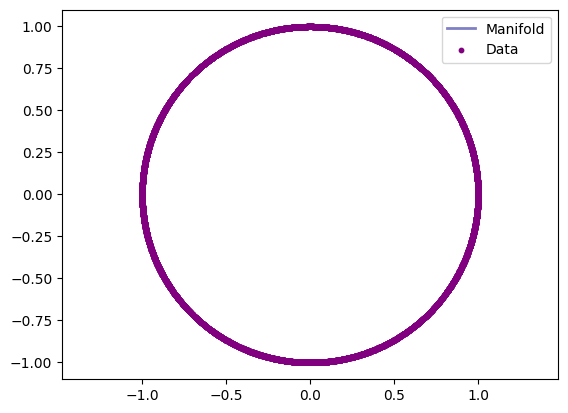

In [38]:
#100 points for visualization purposes
plt.plot(manifold[:,0], manifold[:,1], c = 'darkblue', linewidth = 2, label = 'Manifold', zorder = 1, alpha = 0.5)

plt.scatter(x = dataset[:,0], y = dataset[:,1], c = 'purple', s = 10, alpha = 1, label = 'Data', zorder = 2)
plt.savefig("circle.png", dpi=300, bbox_inches="tight")
plt.axis('equal') 
plt.legend()
plt.show()



### Manifold: Spiral

In [21]:
N = 10000 #sample size
c = 0.5

t_max = 4 * np.pi
u = np.random.uniform(0, 1, N)
t = t_max * np.sqrt(u)
x = c * t * np.cos(t)
y = c * t * np.sin(t)
dataset = np.column_stack((x, y))

t_domain = np.linspace(0, 4*np.pi, 1000)
manifold = np.column_stack((c*np.cos(t_domain)*t_domain,c*np.sin(t_domain)*t_domain))
manifold = (manifold - np.mean(dataset, axis=0)) / np.std(dataset, axis=0) #manif standardized
dataset = (dataset - np.mean(dataset, axis=0)) / np.std(dataset, axis=0) #data standardized

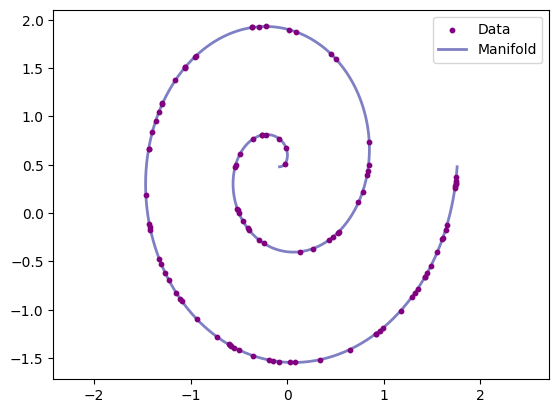

In [14]:
plt.scatter(x = dataset[:,0], y = dataset[:,1], c = 'purple', s = 10, alpha = 1, label = 'Data', zorder = 2)
plt.plot(manifold[:,0], manifold[:,1], c = 'darkblue', linewidth = 2, label = 'Manifold', zorder = 1, alpha = .5)
plt.savefig("spiral.png", dpi=300, bbox_inches="tight")
plt.axis('equal') 
plt.legend()
plt.show()


#### We see that a huge part of the manifold is modeled by a small part of the time interval from which we are sampling uniformly

### Manifold: Staright Line

In [73]:
N = 1000 # sample size
length = 10.0 # length of the line
t = np.random.uniform(-length/2, length/2, N)
x = t + np.random.normal(scale=0.1, size=N)
y = np.zeros(N) 

dataset = np.column_stack((x, y))
t_domain = np.linspace(-length/2, length/2, 1000)
manifold = np.column_stack((t_domain, np.zeros(1000)))

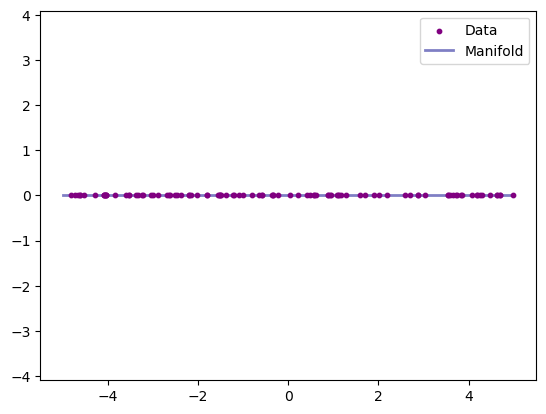

In [72]:
plt.scatter(x = dataset[:,0], y = dataset[:,1], c = 'purple', s = 10, alpha = 1, label = 'Data', zorder = 2)
plt.plot(manifold[:,0], manifold[:,1], c = 'darkblue', linewidth = 2, label = 'Manifold', zorder = 1, alpha = .5)
plt.axis('equal') 
plt.legend()
plt.show()

### Manifold: S-shape

In [65]:
N = 10000

#using arclengths tp sample uniformly
y_dense = np.linspace(-2, 2, 10000)
x_dense = np.sin(y_dense * (np.pi / 2))
deltas = np.sqrt(np.diff(x_dense)**2 + np.diff(y_dense)**2)
cumulative_distance = np.concatenate(([0], np.cumsum(deltas)))
total_length = cumulative_distance[-1]
random_distances = np.random.uniform(0, total_length, N)
y_val = np.interp(random_distances, cumulative_distance, y_dense)
x_val = np.sin(y_val * (np.pi / 2))

# Combine into your final dataset
dataset = np.column_stack((x_val, y_val))

y_domain = np.linspace(-2, 2, 1000)
manifold = np.column_stack((np.sin(y_domain * (np.pi / 2)), y_domain))

manifold = (manifold - np.mean(dataset, axis=0)) / np.std(dataset, axis=0) #manif standardized
dataset = (dataset - np.mean(dataset, axis=0)) / np.std(dataset, axis=0) #data standardized

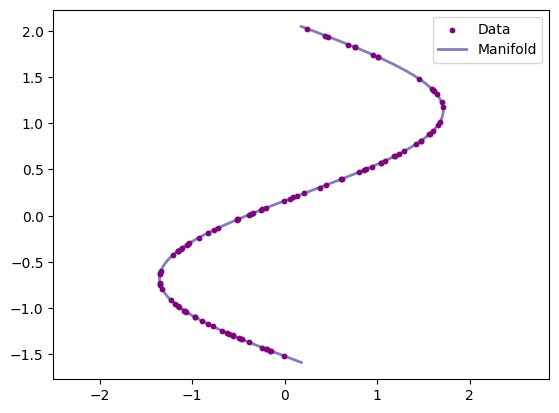

In [12]:
plt.scatter(x = dataset[:,0], y = dataset[:,1], c = 'purple', s = 10, alpha = 1, label = 'Data', zorder = 2)
plt.plot(manifold[:,0], manifold[:,1], c = 'darkblue', linewidth = 2, label = 'Manifold', zorder = 1, alpha = .5)
plt.savefig("s_shape.png", dpi=300, bbox_inches="tight")
plt.axis('equal') 
plt.legend()
plt.show()


### Forward Gaussian and NN Architecture

In [4]:
def time_embedding(t, dim=32):
    """for learning curvature"""
    freqs = torch.exp(
        torch.linspace(0, np.log(1000), dim//2)
    )
    args = t * freqs[None, :]
    return torch.cat([t*torch.sin(args), t*torch.cos(args)], dim=-1)
class score_nn(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(34,256),
            nn.ReLU(),
            nn.Linear(256,512),
            nn.ReLU(),
            nn.Linear(512,256),
            nn.ReLU(),
            nn.Linear(256,2))
    def forward(self, x_noisy, t):
        t_emb = time_embedding(t)
        input_features = torch.cat([x_noisy, t_emb], dim=1) 
        return self.net(input_features)

In [37]:
model = score_nn() #model initialization
L2loss = nn.MSELoss() #L2 loss
optimizer = optim.Adam(model.parameters(), lr=1e-3) #optimizer
sigma_q = 1 #terminal sigma from the paper, NOT PER-STEP ???
# Conver clean manifold to a tensor
data_tens = torch.tensor(dataset, dtype=torch.float32) #data in tensor form
epochs = 10000
dt = 0.001

for epoch in range(epochs):
    optimizer.zero_grad()
    #Sample random times for all points between 0 and 1
    t = torch.rand(N, 1) * (1.0 - dt)  # in [0, 1 - dt]

    noise = torch.randn(N, 2) #save true noise
    #Forward Process
    x_t = data_tens + noise * torch.sqrt(t)*sigma_q
    x_t1 = x_t + torch.randn(N, 2) * np.sqrt(dt)*sigma_q
    #predict noise
    mu_t = model(x_t1, t + dt)
    #L2 loss
    L = L2loss(mu_t, x_t)
    #updating weights
    L.backward()
    optimizer.step()
    
    if epoch % 200 == 0:
        print(f"Epoch {epoch} | Loss: {L.item()}")

Epoch 0 | Loss: 1.5079214572906494
Epoch 200 | Loss: 0.0015416158130392432
Epoch 400 | Loss: 0.0013710170751437545
Epoch 600 | Loss: 0.0012295859633013606
Epoch 800 | Loss: 0.0013856937875971198
Epoch 1000 | Loss: 0.0013337577693164349
Epoch 1200 | Loss: 0.0013842449989169836
Epoch 1400 | Loss: 0.0013485982781276107
Epoch 1600 | Loss: 0.0011102486168965697
Epoch 1800 | Loss: 0.0013398209121078253
Epoch 2000 | Loss: 0.0011134963715448976
Epoch 2200 | Loss: 0.001110703102312982
Epoch 2400 | Loss: 0.0011825538240373135
Epoch 2600 | Loss: 0.0010949760908260942
Epoch 2800 | Loss: 0.0010951549047604203
Epoch 3000 | Loss: 0.0011906694853678346
Epoch 3200 | Loss: 0.0011837134370580316
Epoch 3400 | Loss: 0.0010713710216805339
Epoch 3600 | Loss: 0.0011740600457414985
Epoch 3800 | Loss: 0.001183625077828765
Epoch 4000 | Loss: 0.001072032144293189
Epoch 4200 | Loss: 0.0010704959277063608
Epoch 4400 | Loss: 0.001105432864278555
Epoch 4600 | Loss: 0.0010492720175534487
Epoch 4800 | Loss: 0.001059910

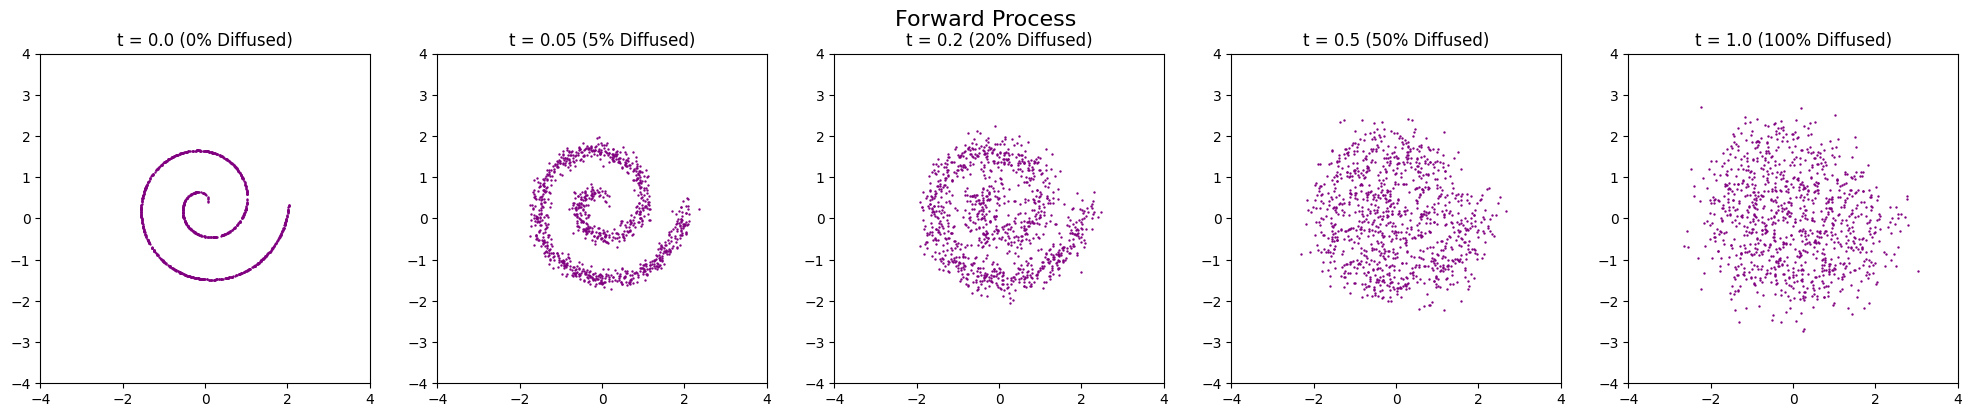

In [36]:
time_steps = [0.0, 0.05, 0.2, 0.5, 1.0]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i, t_val in enumerate(time_steps):
    noise = torch.randn(N, 2)
    
    x_t = data_tens + noise * torch.sqrt(torch.tensor(t_val))*sigma_q
    
    axes[i].scatter(x_t[:, 0].numpy(), x_t[:, 1].numpy(), s=0.5, color='purple',  alpha=1)
    #axes[i].plot(manifold[:, 0], manifold[:, 1], color='purple', linewidth=2, alpha=0.8)
    axes[i].set_title(f"t = {t_val} ({(t_val*100):.0f}% Diffused)")
    
    axes[i].set_xlim(-4, 4); axes[i].set_ylim(-4, 4)
    #axes[i].set_xlim(-2, 2); axes[i].set_ylim(-2, 2)
    
    axes[i].set_aspect('equal', adjustable='box') 

plt.savefig("forward_process.png", dpi=300, bbox_inches="tight")
plt.suptitle("Forward Process", fontsize=16)
plt.tight_layout()
plt.show()

### DDPM Reverse Sampling

In [42]:
x = torch.randn(1000, 2) * sigma_q
dt = 0.01
t_current = 1
with torch.no_grad():
    while t_current > 0:
        t_tensor = torch.full((1000, 1), t_current) #tensored current time for each datapoint 
        mu = model(x, t_tensor)
        eta = torch.randn(1000, 2)*sigma_q*np.sqrt(t_current)
        x = mu + eta
        t_current -= dt

### Staright Line

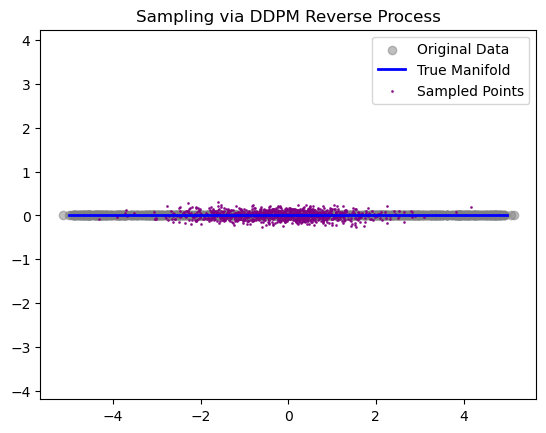

In [76]:
#plt.scatter(dataset[:, 0], dataset[:, 1], alpha=0.5, color='gray', label='Original Data')
plt.plot(manifold[:, 0], manifold[:, 1], color='blue', linewidth=2, label='True Manifold', alpha = .3)
plt.scatter(x[:, 0].numpy(), x[:, 1].numpy(), color='purple', s=1, alpha=0.8, label='Sampled Points')
plt.savefig("forward_process.png", dpi=300, bbox_inches="tight")

plt.axis('equal')
plt.legend()
plt.title("Sampling via DDIM Reverse Process")
plt.show()

### Circle

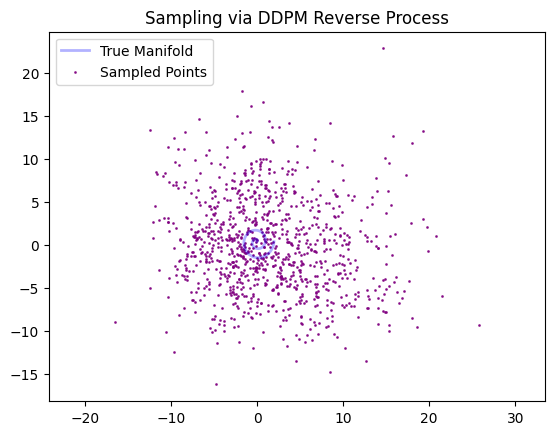

In [43]:
#plt.scatter(dataset[:, 0], dataset[:, 1], alpha=0.5, color='gray', label='Original Data')
plt.plot(manifold[:, 0], manifold[:, 1], color='blue', linewidth=2, label='True Manifold', alpha = .3)
plt.scatter(x[:, 0].numpy(), x[:, 1].numpy(), color='purple', s=1, alpha=0.8, label='Sampled Points')
plt.savefig("circle_samp.png", dpi=300)

plt.axis('equal')
plt.legend()
plt.title("Sampling via DDPM Reverse Process")
plt.show()

### S-shape

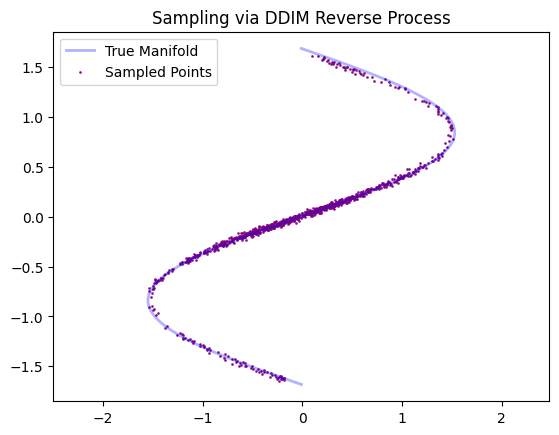

In [68]:
#plt.scatter(dataset[:, 0], dataset[:, 1], alpha=0.5, color='gray', label='Original Data')
plt.plot(manifold[:, 0], manifold[:, 1], color='blue', linewidth=2, label='True Manifold', alpha = .3)
plt.scatter(x[:, 0].numpy(), x[:, 1].numpy(), color='purple', s=1, alpha=0.8, label='Sampled Points')

plt.axis('equal')
plt.legend()
plt.title("Sampling via DDIM Reverse Process")
plt.show()

### Swiss Spiral

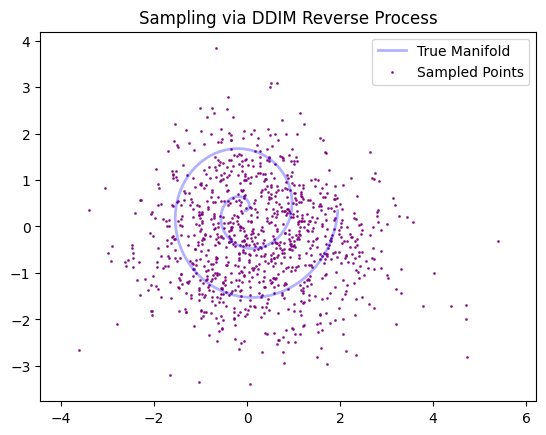

In [41]:
#plt.scatter(dataset[:, 0], dataset[:, 1], alpha=0.5, color='gray', label='Original Data')
plt.plot(manifold[:, 0], manifold[:, 1], color='blue', linewidth=2, label='True Manifold', alpha = .3)
plt.scatter(x[:, 0].numpy(), x[:, 1].numpy(), color='purple', s=1, alpha=0.8, label='Sampled Points')

plt.axis('equal')
plt.legend()
plt.title("Sampling via DDIM Reverse Process")
plt.show()